<center><h1>Feature Engineering</h1>
After looking at the quality of the data through exploratory data analysis, we will apply data cleaning and processing.</center>

## Import package and Load Processed Data

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("df_processed.csv")

## Rolling Metric
Since all numerical features, like `dpm` or `kills`, are data we will only know after the game had concluded, there will be data leakage if we use same-day game stats to predict the same game result. To circumvent data leakage, we will implement a rolling 5-step average for each metric, with a minimum of 3-step window for teams that has smaller historical data.

In [3]:
# Sort chronologically
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values(by=['date']).reset_index(drop=True)

In [4]:
# Calculate rolling past match averages grouped by team
cols_to_be_rolled = df.select_dtypes(include=["number"]).columns
num_matches = 5

for col in cols_to_be_rolled:
  col_name = f"{col}_rolling_avg_{num_matches}"
  # Group by team and calculate rolling mean, shifting by 1 so we don't leak the current match stats
  df[col_name] = (
      df.groupby("teamname")[col]
      .shift(1)
      .rolling(window=num_matches, min_periods=3)
      .mean()
  )

In [5]:
# Drop rows where rolling features are NaN (i.e., each team's first match)
df = df.dropna().reset_index(drop=True)

## *"diff"* Features
A team can win or loss whether they have 50 kills or 20 kills. What matters is their kill advantage over the opponent. Just like with `golddiffatXX` or `xpdiffatXX`, we're going to create `killsdiffatXX` and `baronsdiff` features

In [6]:
# Create the diff features by subracting opp stats to team stats
diff_features = ['barons', 'killsat10', 'killsat15', 'killsat20']

for feat in diff_features:
    df[f'{feat}diff_rolling_avg_{num_matches}'] = df[f'{feat}_rolling_avg_{num_matches}'] - df[f'opp_{feat}_rolling_avg_{num_matches}']
    df = df.drop(['{feat}_rolling_avg_{num_matches}', f'opp_{feat}_rolling_avg_{num_matches}'], axis='columns', errors="ignore")

## Removing Non-Diff Features
Absolute team stats would create noise and may mislead the model. The features that has no corresponding opp stats are leftovers.

In [7]:
non_diff = ['kills', 'deaths', 'dpm', 'damagetakenperminute', 'wardskilled_rolling', 'totalgold']

for col in non_diff:
    df = df.drop([f'{col}_rolling_avg_5',], axis='columns', errors="ignore")

## Data Readiness
The data is almost ready for modeling. We will just have to remove the identifiers like `gameid` and `date`, and drop same-day features like `kills` and `deaths`. We only need the rolling averages for modeling. Finally, we will encode `split` for chronological validation splitting during modeling.

In [8]:
# Drop identifiers
df = df.drop(['gameid', 'league', 'date', 'teamname'], axis='columns', errors='ignore')

In [9]:
cols_to_drop = [x for x in cols_to_be_rolled if x != 'result']

# Dropping same-day features
df = df.drop(cols_to_drop, axis='columns', errors='ignore')

In [10]:
# One-Hot Enconde split and dropping the first column to remove multicollinearity
df = pd.get_dummies(df, columns=['split'], drop_first=True)

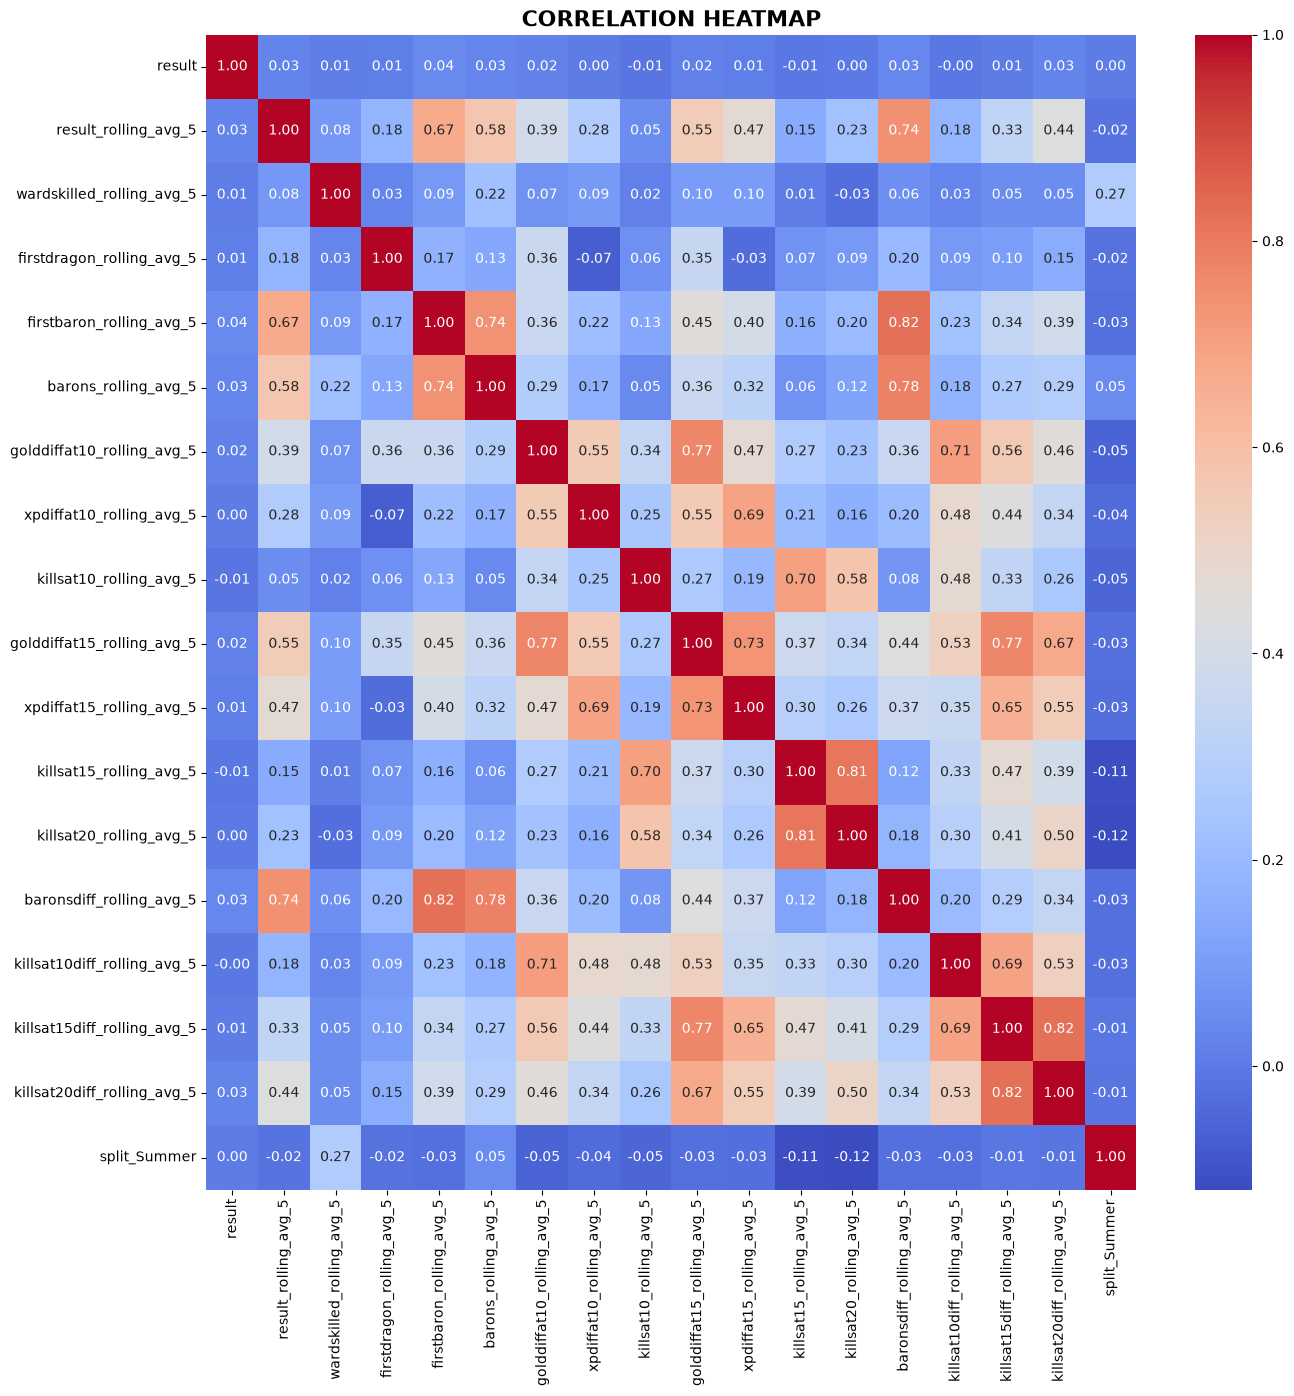

In [11]:
# Compute correlation matrix
co_mtx = df.corr(numeric_only=True)

# Plot correlation heatmap
plt.figure(figsize=(15, 15))
sns.heatmap(co_mtx, cmap='coolwarm', annot=True, fmt='.2f')
plt.title('CORRELATION HEATMAP', fontsize=16, fontweight="bold")
plt.show()

In [12]:
# Quick snapshot of the dataframe ready for modeling
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 18 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   result                       1462 non-null   int64  
 1   result_rolling_avg_5         1462 non-null   float64
 2   wardskilled_rolling_avg_5    1462 non-null   float64
 3   firstdragon_rolling_avg_5    1462 non-null   float64
 4   firstbaron_rolling_avg_5     1462 non-null   float64
 5   barons_rolling_avg_5         1462 non-null   float64
 6   golddiffat10_rolling_avg_5   1462 non-null   float64
 7   xpdiffat10_rolling_avg_5     1462 non-null   float64
 8   killsat10_rolling_avg_5      1462 non-null   float64
 9   golddiffat15_rolling_avg_5   1462 non-null   float64
 10  xpdiffat15_rolling_avg_5     1462 non-null   float64
 11  killsat15_rolling_avg_5      1462 non-null   float64
 12  killsat20_rolling_avg_5      1462 non-null   float64
 13  baronsdiff_rolling_avg_5     

In [13]:
df.to_csv("df_ready.csv", index=False)